# Prueba - Modelos avanzados y redes neuronales
**Módulo 6** · Rafael Riesco · G122

La prueba tiene dos partes:
- **Parte A (pasos 1 a 4):** clasificación de noticias verdaderas y falsas con una red neuronal recurrente **LSTM** y un word embedding pre-entrenado (Word2Vec de Google News).
- **Parte B (pasos 5 a 11):** predicción de la cantidad de veces que se comparte un artículo de Mashable (regresión), comparando **Random Forest**, una **red Fully Connected**, **XGBoost** y **Bagging heterogéneo**.

**Ejecución:** notebook preparado para **Google Colab con GPU**. Los archivos `news1.csv`, `news_pred.csv`, `OnlineNewsPopularity.csv` y `util_bagging.py` deben estar en una carpeta de Google Drive (ver celda de configuración). El Word2Vec de Google se descarga desde el enlace del enunciado.

## 0. Configuración del entorno

In [16]:
import os, sys, shutil, glob, gc, time, subprocess

CARPETA_DRIVE = '/content/drive/MyDrive/prueba_m6'   # <-- ajustar si es necesario
CARPETA_LOCAL = '/content/prueba'

from google.colab import drive
drive.mount('/content/drive')

os.makedirs(CARPETA_LOCAL, exist_ok=True)
for f in glob.glob(os.path.join(CARPETA_DRIVE, '*')):
    if os.path.isfile(f) and not os.path.exists(os.path.join(CARPETA_LOCAL, os.path.basename(f))):
        shutil.copy(f, CARPETA_LOCAL)
os.chdir(CARPETA_LOCAL)
sys.path.append(CARPETA_LOCAL)
print('Archivos disponibles:', sorted(os.listdir(CARPETA_LOCAL)))

# gensim no viene instalado en Colab
try:
    import gensim
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gensim'], check=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos disponibles: ['GoogleNews-vectors-negative300.txt', 'OnlineNewsPopularity.csv', 'archivo.bin', 'download', 'news1.csv', 'news_pred.csv', 'util_bagging.py']


In [17]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, roc_curve,
                             roc_auc_score, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import gdown
from gensim.models import KeyedVectors

keras.utils.set_random_seed(42)
GPU = len(tf.config.list_physical_devices('GPU')) > 0
print('TensorFlow:', tf.__version__, '| GPU disponible:', GPU)
plt.style.use('seaborn-v0_8-whitegrid')

TensorFlow: 2.21.0 | GPU disponible: True


# PARTE A · Clasificación de noticias falsas con LSTM

## 1. Carga, conteo por clase, división y frecuencias de palabras

In [18]:
news_raw = pd.read_csv('news1.csv')
print('Dimensión original:', news_raw.shape)
print('\nValores de la columna label (los 5 más frecuentes):')
print(news_raw['label'].value_counts(dropna=False).head(5))

# Eliminar noticias duplicadas evita que una misma noticia quede en train y en test (fuga de información).
# Si se quisiera reproducir el enunciado sin esta limpieza, cambiar a False.
ELIMINAR_DUPLICADOS = True

# Limpieza: el archivo trae filas mal formadas (textos cortados en varias filas)
news = news_raw[news_raw['label'].isin(['FAKE', 'REAL'])].dropna(subset=['text']).copy()
news['title'] = news['title'].fillna('')
n_invalidas = len(news_raw) - len(news)
n_duplicadas = news.duplicated(['title', 'text']).sum()
if ELIMINAR_DUPLICADOS:
    news = news.drop_duplicates(['title', 'text'])
news = news.reset_index(drop=True)
print(f'\nFilas con etiqueta inválida o sin texto eliminadas: {n_invalidas}')
print(f'Noticias duplicadas: {n_duplicadas} ({"eliminadas" if ELIMINAR_DUPLICADOS else "conservadas"})')

# Se usa título + texto como entrada; la clase positiva (1) es la noticia FALSA
news['contenido'] = (news['title'] + '. ' + news['text']).str.strip()
news['y'] = (news['label'] == 'FAKE').astype(int)

conteo = pd.DataFrame({'noticias': news['label'].value_counts(),
                       'porcentaje': (news['label'].value_counts(normalize=True) * 100).round(1)})
print('\nConteo por clase (datos limpios):')
print(conteo)

X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    news['contenido'], news['y'], test_size=0.33, random_state=42, stratify=news['y'])
print(f'\nTrain: {len(X_train_txt)} | Test: {len(X_test_txt)}')

Dimensión original: (6377, 5)

Valores de la columna label (los 5 más frecuentes):
label
FAKE                                                                                                                                      3186
REAL                                                                                                                                      3154
NaN                                                                                                                                         33
 we have now learned that they don’t even share the same religion.                                                                           2
 usually sex-related. It also involves at least minor sacrifices: one “recipe” calls for cutting one’s figure and “eat[ing] the pain.”       2
Name: count, dtype: int64

Filas con etiqueta inválida o sin texto eliminadas: 74
Noticias duplicadas: 2643 (eliminadas)

Conteo por clase (datos limpios):
       noticias  porcentaje
label       

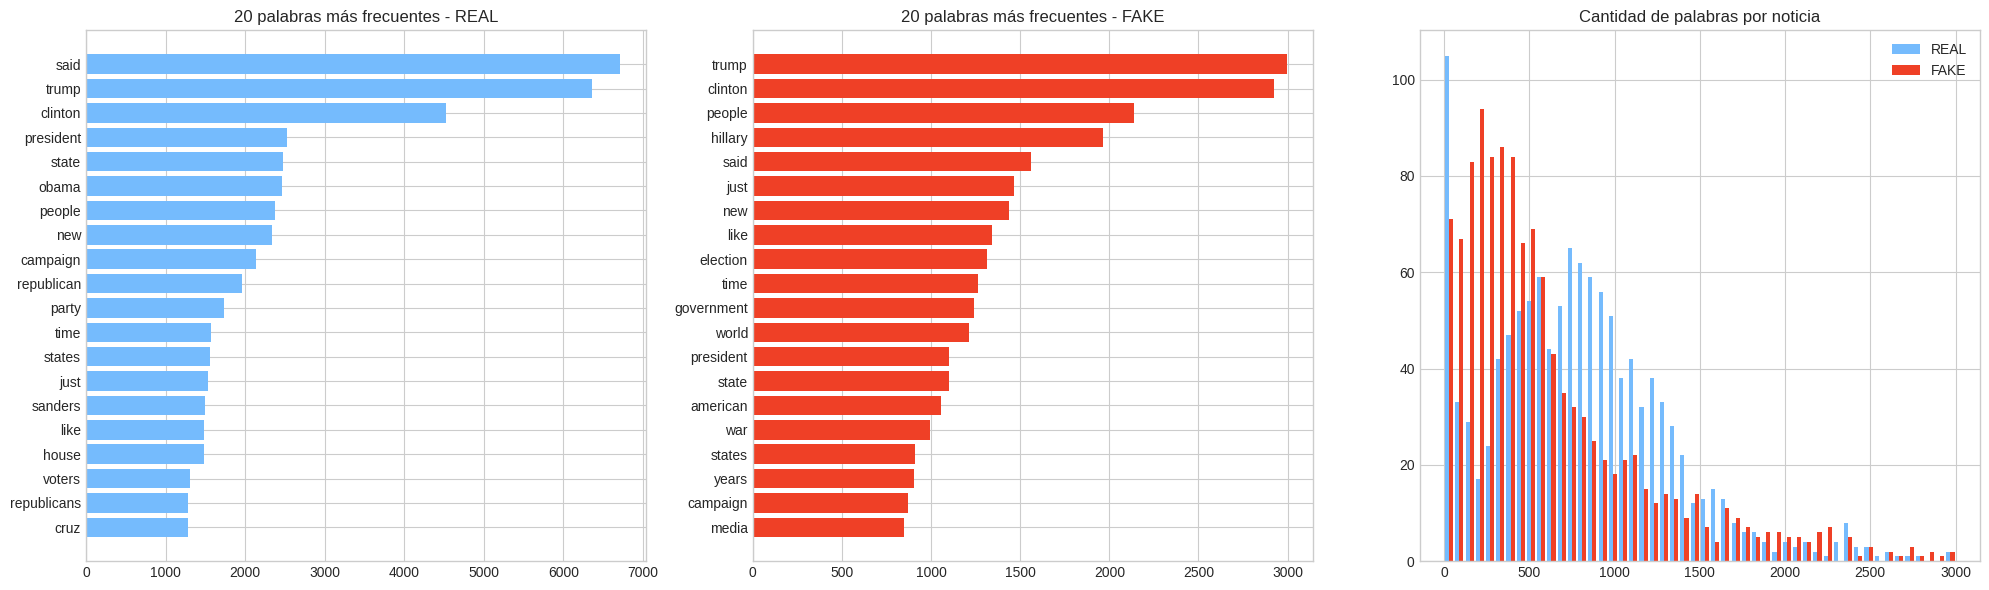

Palabras frecuentes exclusivas del top 20 de cada clase:
  REAL: ['cruz', 'house', 'obama', 'party', 'republican', 'republicans', 'sanders', 'voters']
  FAKE: ['american', 'election', 'government', 'hillary', 'media', 'war', 'world', 'years']

Mediana de palabras -> REAL: 776 | FAKE: 452


In [19]:
# Exploración de frecuencias de palabras (conjunto de entrenamiento, sin stopwords)
def top_palabras(textos, n=20):
    cv = CountVectorizer(stop_words='english', token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
    matriz = cv.fit_transform(textos)
    frec = pd.Series(np.asarray(matriz.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return frec.sort_values(ascending=False).head(n)

top_real = top_palabras(X_train_txt[y_train_txt == 0])
top_fake = top_palabras(X_train_txt[y_train_txt == 1])

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].barh(top_real.index[::-1], top_real.values[::-1], color='xkcd:sky blue')
axes[0].set_title('20 palabras más frecuentes - REAL')
axes[1].barh(top_fake.index[::-1], top_fake.values[::-1], color='xkcd:tomato')
axes[1].set_title('20 palabras más frecuentes - FAKE')
largo = X_train_txt.str.split().str.len()
axes[2].hist([largo[y_train_txt == 0], largo[y_train_txt == 1]], bins=50, range=(0, 3000),
             label=['REAL', 'FAKE'], color=['xkcd:sky blue', 'xkcd:tomato'])
axes[2].set_title('Cantidad de palabras por noticia'); axes[2].legend()
plt.tight_layout(); plt.show()

print('Palabras frecuentes exclusivas del top 20 de cada clase:')
print('  REAL:', sorted(set(top_real.index) - set(top_fake.index)))
print('  FAKE:', sorted(set(top_fake.index) - set(top_real.index)))
print('\nMediana de palabras -> REAL:', int(largo[y_train_txt == 0].median()),
      '| FAKE:', int(largo[y_train_txt == 1].median()))

**Observación:** tras la limpieza quedan 3.660 noticias balanceadas (1.846 REAL y 1.814 FAKE). Las palabras frecuentes exclusivas de las noticias reales se refieren a la política electoral concreta (*obama*, *republican*, *sanders*, *cruz*, *voters*, *party*), mientras en las falsas predominan términos más generales y de confrontación (*hillary*, *media*, *war*, *government*, *world*). Las noticias falsas son además más cortas (mediana de 452 palabras vs 776).

## 2. Word2Vec pre-entrenado, tokenización, padding y matriz de embedding
Se descarga el Word2Vec de Google News (3 millones de palabras, 300 dimensiones) desde el enlace del enunciado y se carga con `KeyedVectors`.

**Tokenización:** se usa la capa `TextVectorization` de Keras (en Keras 3 ya no existe el `Tokenizer` clásico), con un vocabulario máximo de **80.000 palabras** construido solo con el conjunto de entrenamiento, y secuencias de largo **80** (se conservan las primeras 80 palabras; las noticias más cortas se completan con ceros: *padding*). El índice 0 se reserva para el padding y el 1 para palabras fuera del vocabulario.

In [20]:
url = 'https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK'
nombre_archivo = 'archivo.bin'
if not os.path.exists(nombre_archivo):
    gdown.download(url, nombre_archivo, quiet=False)

# Si el archivo descargado viene comprimido en gzip, se renombra para que gensim lo lea correctamente
with open(nombre_archivo, 'rb') as f:
    if f.read(2) == b'\x1f\x8b':
        os.rename(nombre_archivo, nombre_archivo + '.gz')
        nombre_archivo += '.gz'

inicio = time.time()
word2vec_model_google = KeyedVectors.load_word2vec_format(nombre_archivo, binary=True)
print(f'Word2Vec cargado en {(time.time() - inicio) / 60:.1f} min: '
      f'{len(word2vec_model_google.key_to_index):,} palabras x {word2vec_model_google.vector_size} dimensiones')

Word2Vec cargado en 0.4 min: 3,000,000 palabras x 300 dimensiones


In [21]:
MAX_VOCAB, MAX_LEN, EMB_DIM = 80000, 80, 300

vectorizador = layers.TextVectorization(max_tokens=MAX_VOCAB, output_sequence_length=MAX_LEN,
                                        standardize='lower_and_strip_punctuation')
vectorizador.adapt(X_train_txt.values)
vocab = vectorizador.get_vocabulary()

seq_train = vectorizador(X_train_txt.values).numpy()
seq_test = vectorizador(X_test_txt.values).numpy()
print('Tamaño del vocabulario:', len(vocab))
print('Secuencias train:', seq_train.shape, '| test:', seq_test.shape)
print('Ejemplo (primeros 15 índices):', seq_train[0][:15])
print('Noticias con padding (más cortas que 80 palabras):', (seq_train == 0).any(axis=1).mean().round(3))

# Matriz de embedding: fila i = vector Word2Vec de la palabra i del vocabulario.
# Word2Vec de Google distingue mayúsculas: se prueba la palabra, con mayúscula inicial y en mayúsculas.
matriz_emb = np.zeros((len(vocab), EMB_DIM), dtype='float32')
encontradas = 0
for i, palabra in enumerate(vocab[2:], start=2):
    for candidata in (palabra, palabra.capitalize(), palabra.upper()):
        if candidata in word2vec_model_google.key_to_index:
            matriz_emb[i] = word2vec_model_google[candidata]
            encontradas += 1
            break
print(f'\nMatriz de embedding: {matriz_emb.shape}')
print(f'Palabras del vocabulario con vector Word2Vec: {encontradas:,} de {len(vocab) - 2:,} '
      f'({encontradas / (len(vocab) - 2):.1%})')

del word2vec_model_google   # libera ~3.6 GB de RAM
gc.collect()

Tamaño del vocabulario: 70660
Secuencias train: (2452, 80) | test: (1208, 80)
Ejemplo (primeros 15 índices): [26362   237   570    39    96   324  1941   578     2   124   155  3942
 22413  5422  1493]
Noticias con padding (más cortas que 80 palabras): 0.088

Matriz de embedding: (70660, 300)
Palabras del vocabulario con vector Word2Vec: 41,589 de 70,658 (58.9%)


**Observación:** el vocabulario construido con el entrenamiento tiene 70.660 palabras (bajo el máximo de 80.000), y solo el 8.8% de las noticias es más corta que 80 palabras y requiere padding. El Word2Vec de Google cubre el 58.9% del vocabulario; las palabras sin vector (nombres propios poco frecuentes, cifras, errores tipográficos y palabras con apóstrofes tipográficos como *couldn’t*) quedan representadas con un vector de ceros. La matriz de embedding tiene 70.660 × 300 pesos.

## 3. Red neuronal recurrente LSTM con Dropout
**Arquitectura** (configuración *many to one* de la guía: secuencia de palabras → una clase):
- **Embedding** con los pesos de Word2Vec, **congelados** (`trainable=False`) para conservar el conocimiento pre-entrenado, y `mask_zero=True` para que las LSTM ignoren el padding.
- **Tres capas LSTM** apiladas (128, 64 y 32 unidades): las dos primeras devuelven la secuencia completa (`return_sequences=True`) para alimentar a la siguiente (RNN multicapa), y la última entrega solo su estado final. Las celdas LSTM, con sus compuertas, mitigan el desvanecimiento del gradiente de las RNN simples.
- **Dropout** (0.3) después de cada LSTM, una capa densa ReLU y la salida **sigmoide** (probabilidad de que la noticia sea falsa).
- Pérdida binary crossentropy, optimizador Adam, **máximo 20 épocas** con parada temprana sobre una validación estratificada del 15% del entrenamiento.

Model: "lstm_fake_news"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 80, 300)        │    21,198,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 80, 128)        │       219,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 80, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 80, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,480,017 (81.94 MB)

 Trainable params: 282,017 (1.08 MB)

 Non-trainable params: 21,198,000 (80.86 MB)

Epoch 1/20
33/33 - 4s - 127ms/step - accuracy: 0.6488 - auc: 0.7043 - loss: 0.6296 - val_accuracy: 0.6223 - val_auc: 0.7436 - val_loss: 0.8715
Epoch 2/20
33/33 - 1s - 22ms/step - accuracy: 0.6943 - auc: 0.7122 - loss: 0.6282 - val_accuracy: 0.7092 - val_auc: 0.7942 - val_loss: 0.5837
Epoch 3/20
33/33 - 1s - 21ms/step - accuracy: 0.7471 - auc: 0.7944 - loss: 0.5474 - val_accuracy: 0.7554 - val_auc: 0.8359 - val_loss: 0.5488
Epoch 4/20
33/33 - 1s - 21ms/step - accuracy: 0.8037 - auc: 0.8487 - loss: 0.4726 - val_accuracy: 0.8152 - val_auc: 0.8796 - val_loss: 0.4471
Epoch 5/20
33/33 - 1s - 19ms/step - accuracy: 0.8215 - auc: 0.8668 - loss: 0.4468 - val_accuracy: 0.7609 - val_auc: 0.8744 - val_loss: 0.5154
Epoch 6/20
33/33 - 1s - 23ms/step - accuracy: 0.8479 - auc: 0.8979 - loss: 0.3935 - val_accuracy: 0.8261 - val_auc: 0.8823 - val_loss: 0.4435
Epoch 7/20
33/33 - 1s - 22ms/step - accuracy: 0.8709 - auc: 0.9195 - loss: 0.3506 - val_accuracy: 0.8370 - val_auc: 0.8999 - val_loss: 0.4129
Epoch

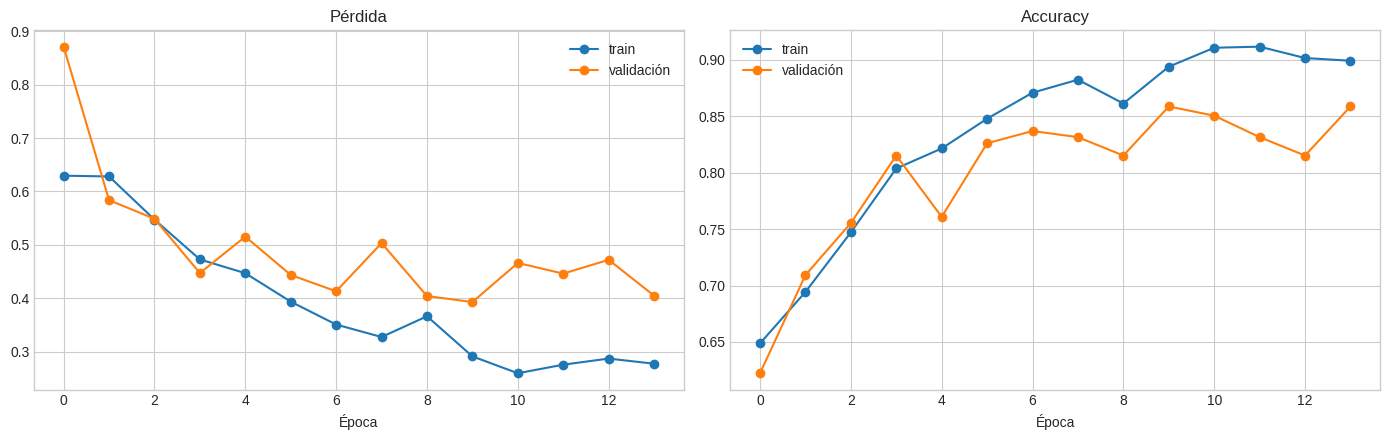

In [22]:
seq_tr, seq_val, y_tr_txt, y_val_txt = train_test_split(seq_train, y_train_txt.values, test_size=0.15,
                                                        random_state=42, stratify=y_train_txt.values)

keras.utils.set_random_seed(42)
modelo_lstm = keras.Sequential([
    keras.Input(shape=(MAX_LEN,), dtype='int64'),
    layers.Embedding(len(vocab), EMB_DIM, embeddings_initializer=keras.initializers.Constant(matriz_emb),
                     trainable=False, mask_zero=True),
    layers.LSTM(128, return_sequences=True),
    layers.Dropout(0.3),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.3),
    layers.LSTM(32),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name='lstm_fake_news')
modelo_lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
                    metrics=['accuracy', keras.metrics.AUC(name='auc')])
modelo_lstm.summary()

inicio = time.time()
hist_lstm = modelo_lstm.fit(seq_tr, y_tr_txt, validation_data=(seq_val, y_val_txt), epochs=20,
                            batch_size=64, verbose=2,
                            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                                                     restore_best_weights=True)])
print(f'Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min | épocas: {len(hist_lstm.history["loss"])}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, t in [(axes[0], 'loss', 'Pérdida'), (axes[1], 'accuracy', 'Accuracy')]:
    ax.plot(hist_lstm.history[m], marker='o', label='train')
    ax.plot(hist_lstm.history['val_' + m], marker='o', label='validación')
    ax.set_title(t); ax.set_xlabel('Época'); ax.legend()
plt.tight_layout(); plt.show()

Accuracy test: 0.8576 | AUC: 0.9292

              precision    recall  f1-score   support

        REAL      0.874     0.839     0.856       609
        FAKE      0.843     0.876     0.859       599

    accuracy                          0.858      1208
   macro avg      0.858     0.858     0.858      1208
weighted avg      0.858     0.858     0.858      1208



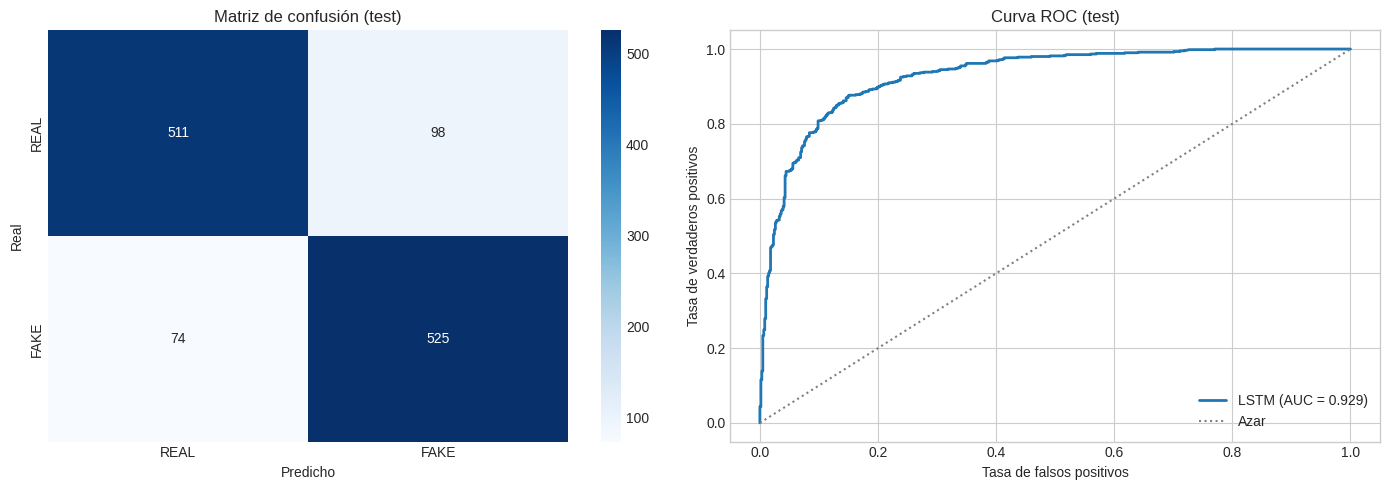

In [23]:
proba_lstm = modelo_lstm.predict(seq_test, verbose=0).ravel()
pred_lstm = (proba_lstm >= 0.5).astype(int)
acc_lstm = accuracy_score(y_test_txt, pred_lstm)
auc_lstm = roc_auc_score(y_test_txt, proba_lstm)
print(f'Accuracy test: {acc_lstm:.4f} | AUC: {auc_lstm:.4f}\n')
print(classification_report(y_test_txt, pred_lstm, target_names=['REAL', 'FAKE'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(y_test_txt, pred_lstm), annot=True, fmt='d', cmap='Blues',
            xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'], ax=axes[0])
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real'); axes[0].set_title('Matriz de confusión (test)')
fpr, tpr, _ = roc_curve(y_test_txt, proba_lstm)
axes[1].plot(fpr, tpr, lw=2, label=f'LSTM (AUC = {auc_lstm:.3f})')
axes[1].plot([0, 1], [0, 1], ls=':', color='gray', label='Azar')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Tasa de verdaderos positivos')
axes[1].set_title('Curva ROC (test)'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

**Observación:** la LSTM alcanza **85.8% de accuracy y AUC de 0.929 en test**, superando la meta de 80%. El desempeño es equilibrado entre clases: precision de 0.874 y recall de 0.839 para REAL, y precision de 0.843 y recall de 0.876 para FAKE. Las curvas muestran que la parada temprana se activó en la época 14, restaurando los pesos con menor pérdida de validación.

## 4. Predicción sobre `news_pred.csv`

In [24]:
news_pred = pd.read_csv('news_pred.csv')
news_pred['contenido'] = (news_pred['title'].fillna('') + '. ' + news_pred['text'].fillna('')).str.strip()
seq_pred = vectorizador(news_pred['contenido'].values).numpy()
news_pred['prob_FAKE'] = modelo_lstm.predict(seq_pred, verbose=0).ravel().round(3)
news_pred['prediccion'] = np.where(news_pred['prob_FAKE'] >= 0.5, 'FAKE', 'REAL')
news_pred['acierto'] = news_pred['prediccion'] == news_pred['label']
pd.set_option('display.max_colwidth', 80)
print(news_pred[['title', 'label', 'prob_FAKE', 'prediccion', 'acierto']].to_string())
print(f"\nAciertos: {news_pred['acierto'].sum()} de {len(news_pred)}")

# Noticia a analizar: la primera en que el modelo se equivoca; si no hay, la de mayor confianza correcta
errores = news_pred[~news_pred['acierto']]
fila = errores.iloc[0] if len(errores) else news_pred.loc[(news_pred['prob_FAKE'] - 0.5).abs().idxmax()]
idx = fila.name
tokens = [vocab[t] for t in seq_pred[idx] if t > 0]
print('\n=== Noticia analizada ===')
print('Título:', fila['title'])
print('Etiqueta real:', fila['label'], '| Predicción:', fila['prediccion'], '| prob_FAKE:', fila['prob_FAKE'])
print('\nLas 80 palabras que "ve" el modelo:\n', ' '.join(tokens))
print(f"\nPalabras fuera del vocabulario ([UNK]): {sum(t == '[UNK]' for t in tokens)} de {len(tokens)}")

                                                                     title label  prob_FAKE prediccion  acierto
0  At least 12 dead after terror attack at Paris newspaper office (+video)  REAL      0.036       REAL     True
1                  World leaders' personal chefs sample Indian market fare  FAKE      0.971       FAKE     True
2                    An Open Letter to Black South African Police Officers  FAKE      0.970       FAKE     True
3                 Gay man finds it in himself to tolerate religious person  FAKE      0.179       REAL    False
4     US Spy Chief: Asking North Korea To Stop Nuke Program a ‘Lost Cause’  FAKE      0.971       FAKE     True
5    The Devastating Consequences Of A 'Small' Rise In Global Temperatures  REAL      0.866       FAKE    False
6   Cost, logistics of Obama immigration plan raise concerns before launch  REAL      0.036       REAL     True

Aciertos: 5 de 7

=== Noticia analizada ===
Título: Gay man finds it in himself to tolerate religious p

**Análisis de la noticia:** el modelo acertó 5 de las 7 noticias. Se analiza el primer error: *"Gay man finds it in himself to tolerate religious person"*, etiquetada **FAKE** y clasificada como **REAL** con una probabilidad de ser falsa de solo 0.179.

- **Es una noticia satírica:** invierte con ironía un estereotipo (un hombre gay que "logra tolerar" a una persona religiosa). Su falsedad no está en el vocabulario sino en la intención.
- **Su redacción imita el estilo periodístico tradicional:** frases neutras, nombres propios ("Tom Booker", "Wayne Hayes"), citas textuales y situaciones cotidianas ("make a cup of tea"). Son rasgos que el modelo asocia con noticias reales; no aparecen términos que en el entrenamiento se asocien a noticias falsas, como *hillary*, *media* o *war*.
- **El modelo solo ve las primeras 80 palabras**, y en este caso el título aparece dos veces (el texto comienza repitiéndolo), por lo que la ventana efectiva es aún menor. Con tan poco contexto, el tono satírico es indistinguible de una nota real.

El otro error (*"The Devastating Consequences Of A 'Small' Rise In Global Temperatures"*, REAL clasificada como FAKE con 0.866) muestra el caso inverso: un tema y un tono alarmista (*devastating*, *global*) frecuentes en las noticias falsas del entrenamiento llevan al modelo a desconfiar de una noticia verdadera. En ambos casos el modelo se apoya en **patrones de vocabulario y tono**, no en la veracidad de los hechos, que es su principal limitación.

# PARTE B · Predicción de la cantidad de veces que se comparte un artículo (Mashable)

## 5. Carga, limpieza de nombres, columnas sin aporte, ausentes y estadísticos

In [25]:
mash = pd.read_csv('OnlineNewsPopularity.csv')
print('Dimensión original:', mash.shape)
print('Nombres originales (ejemplo):', list(mash.columns[:3]))
mash.columns = mash.columns.str.strip()
print('Nombres corregidos (ejemplo):', list(mash.columns[:3]))

# url es un identificador; timedelta describe cuándo se recolectaron los datos, no al artículo
mash = mash.drop(columns=['url', 'timedelta'])
print('\nDimensión tras eliminar url y timedelta:', mash.shape)
print('Valores ausentes totales:', mash.isna().sum().sum())
print('Filas duplicadas:', mash.duplicated().sum())

pd.set_option('display.max_rows', 70)
estadisticos = mash.describe().T
estadisticos['asimetria'] = mash.skew()
estadisticos.round(3)

Dimensión original: (39644, 61)
Nombres originales (ejemplo): ['url', ' timedelta', ' n_tokens_title']
Nombres corregidos (ejemplo): ['url', 'timedelta', 'n_tokens_title']

Dimensión tras eliminar url y timedelta: (39644, 59)
Valores ausentes totales: 0
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max,asimetria
n_tokens_title,39644.0,10.399,2.114,2.000,9.000,10.000,12.000,23.000,0.165
n_tokens_content,39644.0,546.515,471.108,0.000,246.000,409.000,716.000,8474.000,2.945
n_unique_tokens,39644.0,0.548,3.521,0.000,0.471,0.539,0.609,701.000,198.655
n_non_stop_words,39644.0,0.996,5.231,0.000,1.000,1.000,1.000,1042.000,198.792
n_non_stop_unique_tokens,39644.0,0.689,3.265,0.000,0.626,0.690,0.755,650.000,198.443
num_hrefs,39644.0,10.884,11.332,0.000,4.000,8.000,14.000,304.000,4.013
num_self_hrefs,39644.0,3.294,3.855,0.000,1.000,3.000,4.000,116.000,5.173
num_imgs,39644.0,4.544,8.309,0.000,1.000,1.000,4.000,128.000,3.947
num_videos,39644.0,1.250,4.108,0.000,0.000,0.000,1.000,91.000,7.020
average_token_length,39644.0,4.548,0.844,0.000,4.478,4.664,4.855,8.042,-4.576


**Observación:** se corrigen los nombres de las columnas, que comenzaban con un espacio. Se eliminan `url` (identificador del artículo) y `timedelta` (días entre la publicación y la recolección de los datos: describe el proceso de recolección, no al artículo). No hay valores ausentes ni filas duplicadas. Los estadísticos revelan: (1) la variable objetivo `shares` es muy asimétrica (media de 3.395 vs mediana de 1.400, asimetría 34); (2) `n_unique_tokens`, `n_non_stop_words` y `n_non_stop_unique_tokens` deberían ser tasas entre 0 y 1, pero un artículo registra valores de 701, 1.042 y 650, un error de registro que explica su asimetría cercana a 200; (3) 1.181 artículos tienen 0 palabras de contenido; (4) las variables de palabras clave (`kw_*`) y de artículos referenciados tienen escalas de miles a cientos de miles y valores −1 (sin información), lo que hace necesaria la normalización.

## 6. Outliers de `shares` y correlaciones

Límites IQR: [-1835, 5581] | outliers por arriba: 4541 | por abajo: 0
Filas: 39644 -> 35103 (11.5% eliminadas)


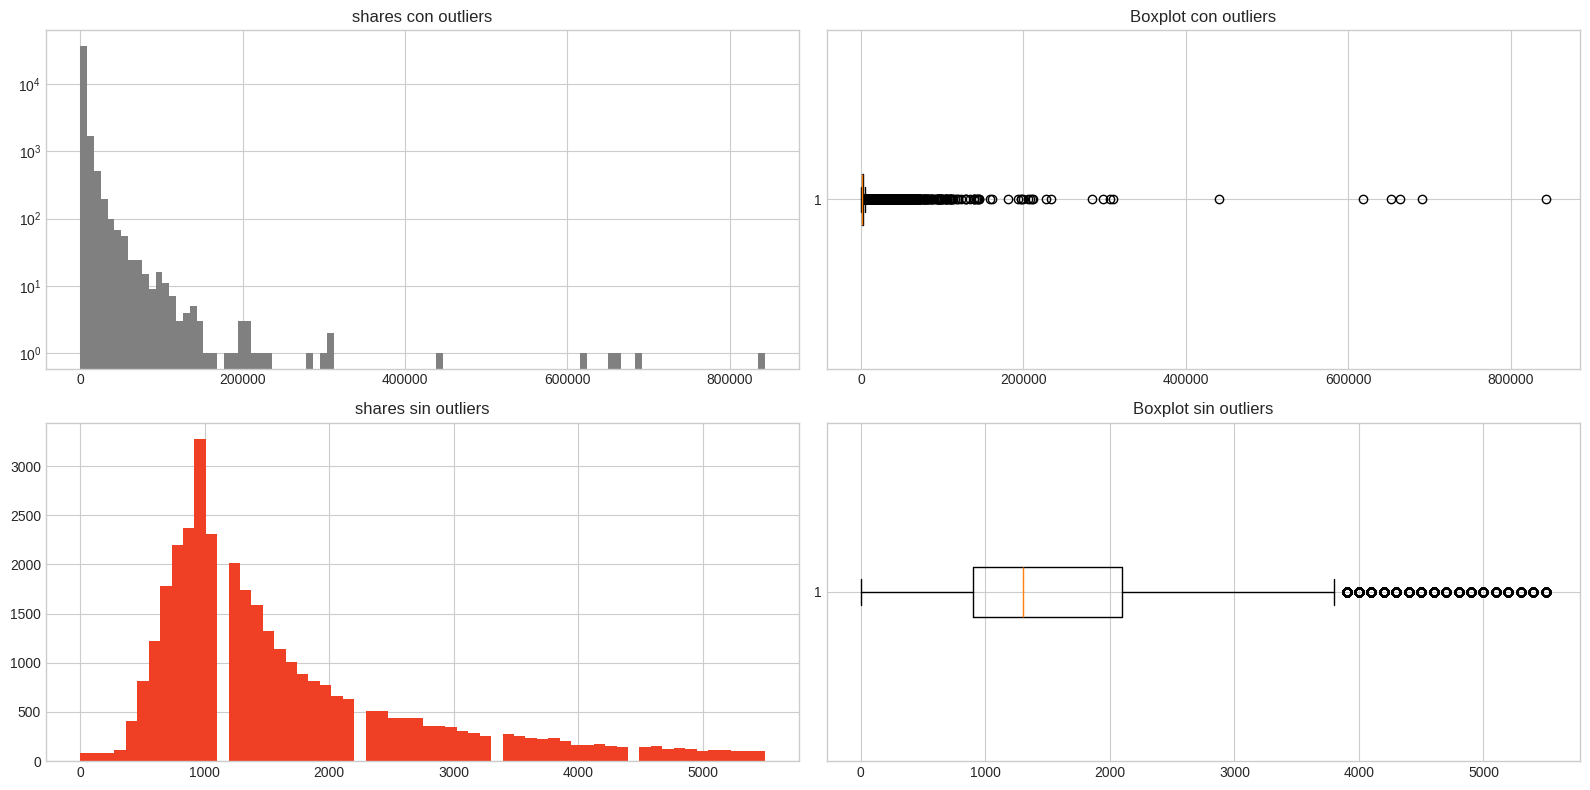

count    35103.0
mean      1672.0
std       1103.2
min          1.0
25%        903.0
50%       1300.0
75%       2100.0
max       5500.0
Name: shares, dtype: float64


In [26]:
q1, q3 = mash['shares'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_sup, out_inf = (mash['shares'] > lim_sup).sum(), (mash['shares'] < lim_inf).sum()
print(f'Límites IQR: [{lim_inf:.0f}, {lim_sup:.0f}] | outliers por arriba: {out_sup} | por abajo: {out_inf}')

mash_sin = mash[mash['shares'].between(lim_inf, lim_sup)].reset_index(drop=True)
print(f'Filas: {len(mash)} -> {len(mash_sin)} ({(1 - len(mash_sin) / len(mash)):.1%} eliminadas)')

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes[0, 0].hist(mash['shares'], bins=100, color='gray'); axes[0, 0].set_title('shares con outliers')
axes[0, 0].set_yscale('log')
axes[0, 1].boxplot(mash['shares'], vert=False); axes[0, 1].set_title('Boxplot con outliers')
axes[1, 0].hist(mash_sin['shares'], bins=60, color='xkcd:tomato'); axes[1, 0].set_title('shares sin outliers')
axes[1, 1].boxplot(mash_sin['shares'], vert=False); axes[1, 1].set_title('Boxplot sin outliers')
plt.tight_layout(); plt.show()
print(mash_sin['shares'].describe().round(1))

**Observación:** shares es extremadamente asimétrica (máximo de 843.300 frente a una mediana de 1.400). Con el criterio de 1.5 IQR hay 4.541 outliers por arriba y ninguno por abajo; al eliminarlos (11.5% de los artículos) la variable queda entre 1 y 5.500 compartidos, con media de 1.672 y mediana de 1.300, aún con asimetría positiva.

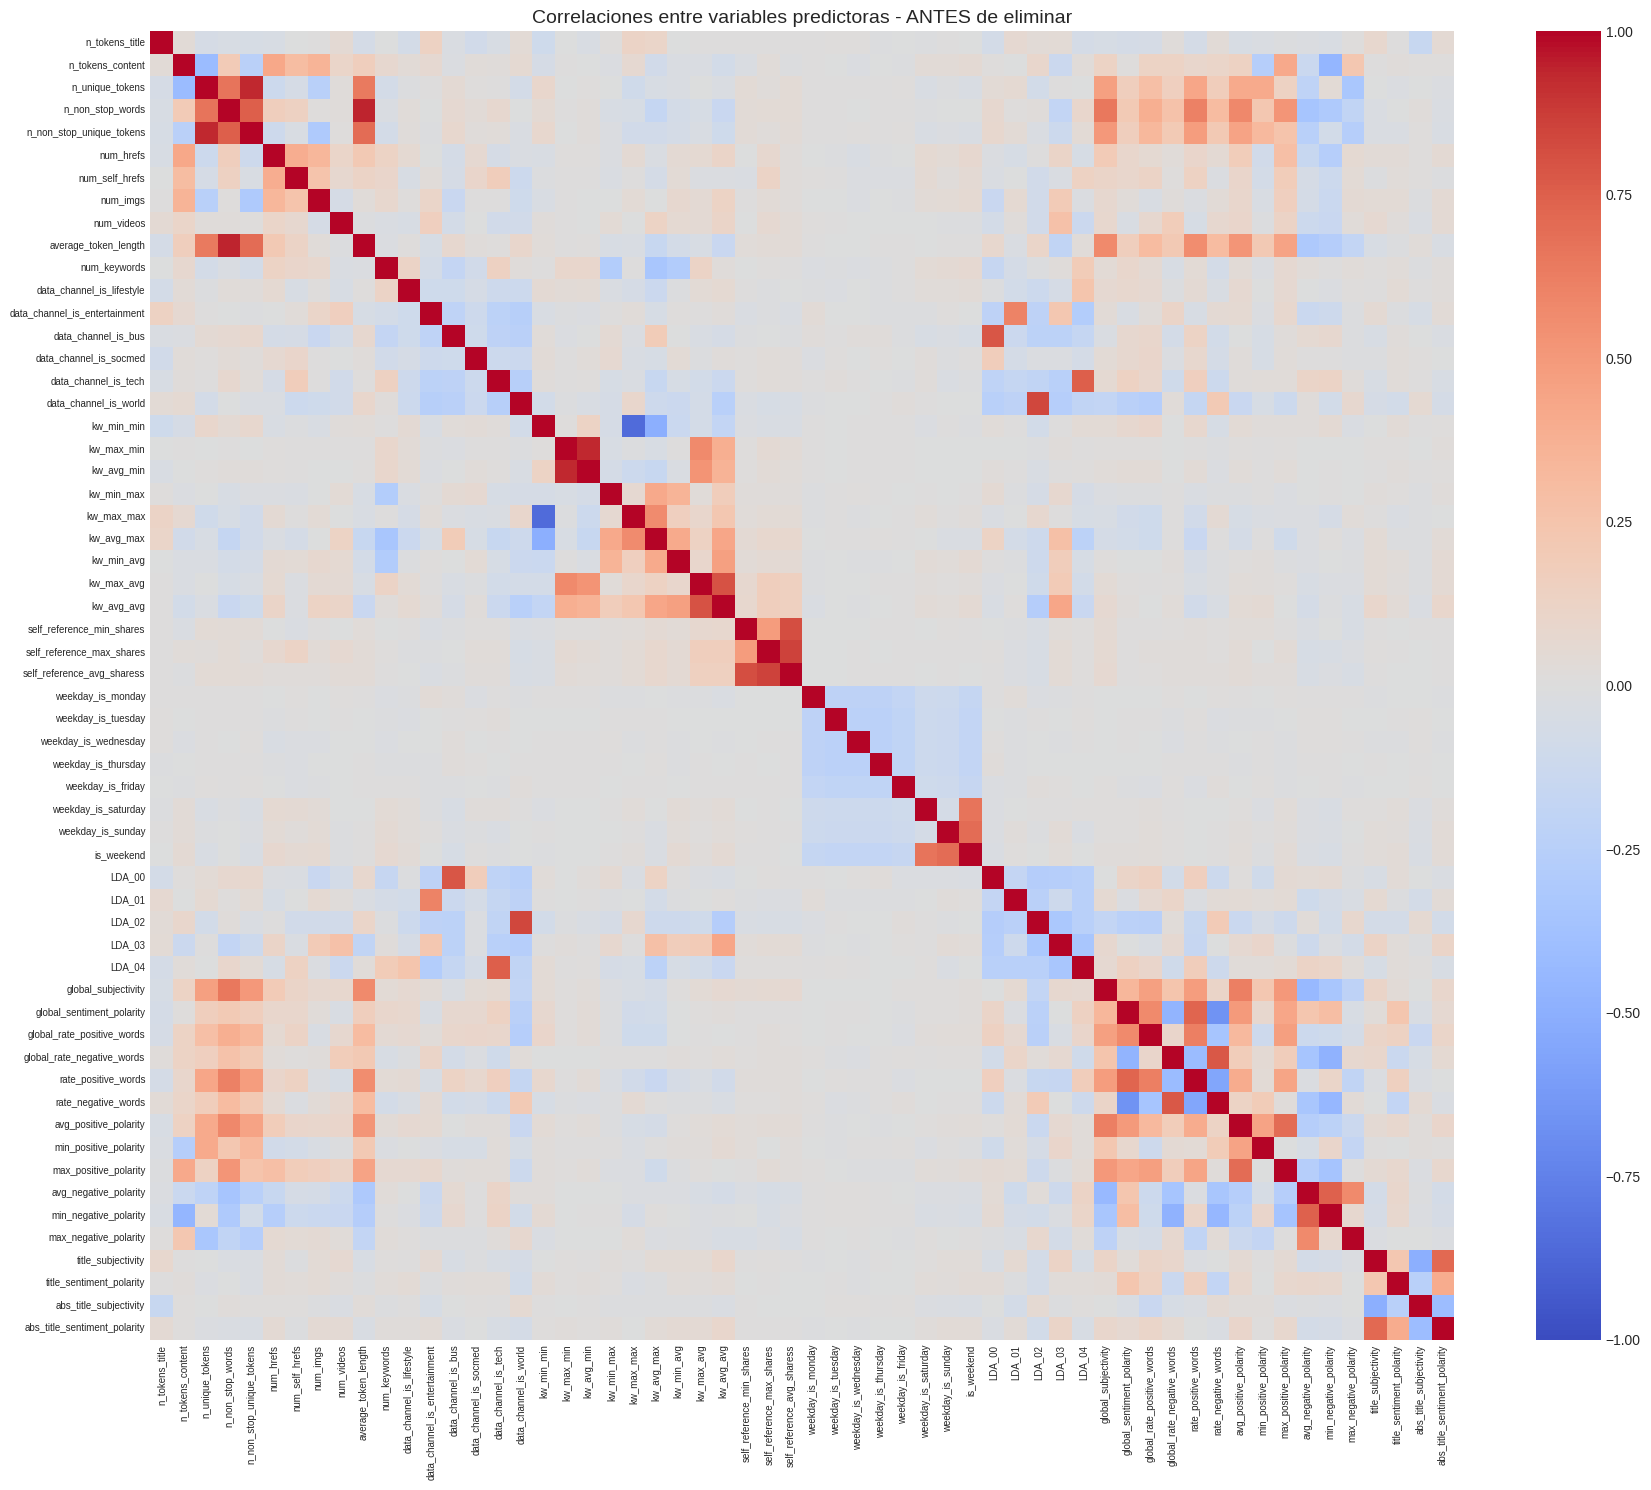

Pares con |correlación| > 0.7: 16
                variable_1                   variable_2  correlacion
          n_non_stop_words         average_token_length        0.941
           n_unique_tokens     n_non_stop_unique_tokens        0.937
                kw_max_min                   kw_avg_min        0.935
                kw_min_min                   kw_max_max       -0.859
 self_reference_max_shares   self_reference_avg_sharess        0.858
     data_channel_is_world                       LDA_02        0.841
 self_reference_min_shares   self_reference_avg_sharess        0.820
                kw_max_avg                   kw_avg_avg        0.797
       data_channel_is_bus                       LDA_00        0.784
global_rate_negative_words          rate_negative_words        0.778
          n_non_stop_words     n_non_stop_unique_tokens        0.757
      data_channel_is_tech                       LDA_04        0.751
     avg_negative_polarity        min_negative_polarity        0.748


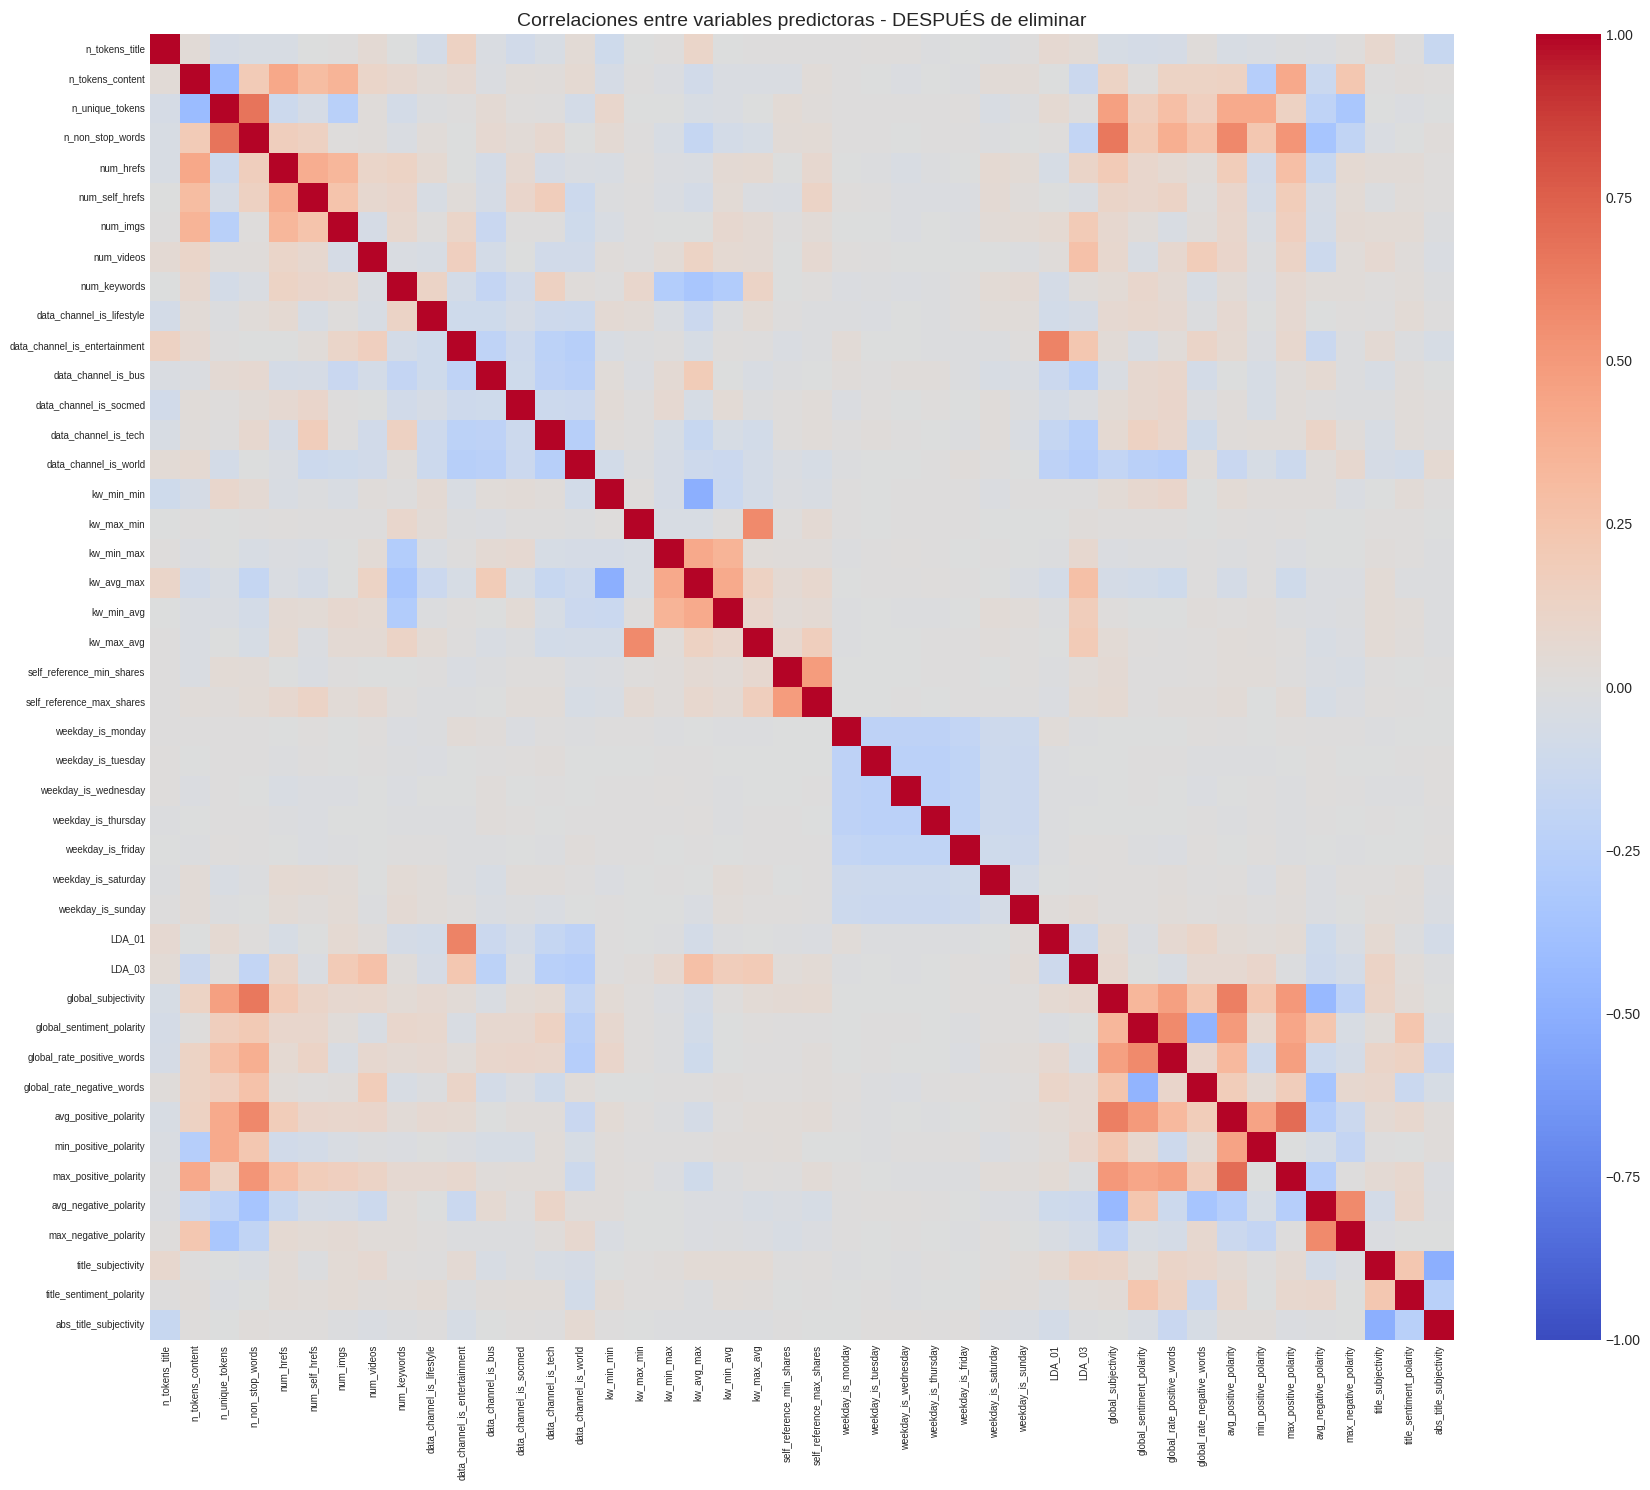

In [27]:
def heatmap_corr(df, titulo):
    plt.figure(figsize=(18, 15))
    sns.heatmap(df.corr(), cmap='coolwarm', vmin=-1, vmax=1, center=0, xticklabels=True, yticklabels=True)
    plt.title(titulo, fontsize=14); plt.xticks(fontsize=7); plt.yticks(fontsize=7)
    plt.tight_layout(); plt.show()

predictoras = mash_sin.drop(columns=['shares'])
heatmap_corr(predictoras, 'Correlaciones entre variables predictoras - ANTES de eliminar')

corr = predictoras.corr()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('correlacion').reset_index().rename(columns={'level_0': 'variable_1', 'level_1': 'variable_2'}))
pares = pares[pares['correlacion'].abs() > 0.7].sort_values('correlacion', key=abs, ascending=False)
print(f'Pares con |correlación| > 0.7: {len(pares)}')
print(pares.round(3).to_string(index=False))

# Se elimina una variable de cada par (la segunda), recorriendo de mayor a menor correlación
eliminadas = []
for _, p in pares.iterrows():
    if p['variable_1'] not in eliminadas and p['variable_2'] not in eliminadas:
        eliminadas.append(p['variable_2'])
print('\nVariables eliminadas:', eliminadas)

mash_final = mash_sin.drop(columns=eliminadas)
pred_final = mash_final.drop(columns=['shares'])
max_corr = pred_final.corr().where(np.triu(np.ones((pred_final.shape[1],) * 2, dtype=bool), k=1)).abs().max().max()
print(f'Variables predictoras: {predictoras.shape[1]} -> {pred_final.shape[1]} | |correlación| máxima restante: {max_corr:.3f}')
heatmap_corr(pred_final, 'Correlaciones entre variables predictoras - DESPUÉS de eliminar')

**Observación:** se encontraron 16 pares con |correlación| > 0.7. Varios corresponden a variables que miden lo mismo (`n_unique_tokens` y `n_non_stop_unique_tokens`, mínimos/máximos/promedios de las mismas palabras clave o de los artículos referenciados), otros a relaciones por construcción (`is_weekend` con `weekday_is_sunday`) y otros a temas LDA asociados a un canal (`LDA_02` con el canal world, `LDA_00` con business, `LDA_04` con tech). Se eliminó una variable de cada par, quedando 44 predictoras con una correlación máxima de 0.695.

## 7. Distribución de cuatro variables, normalización y división

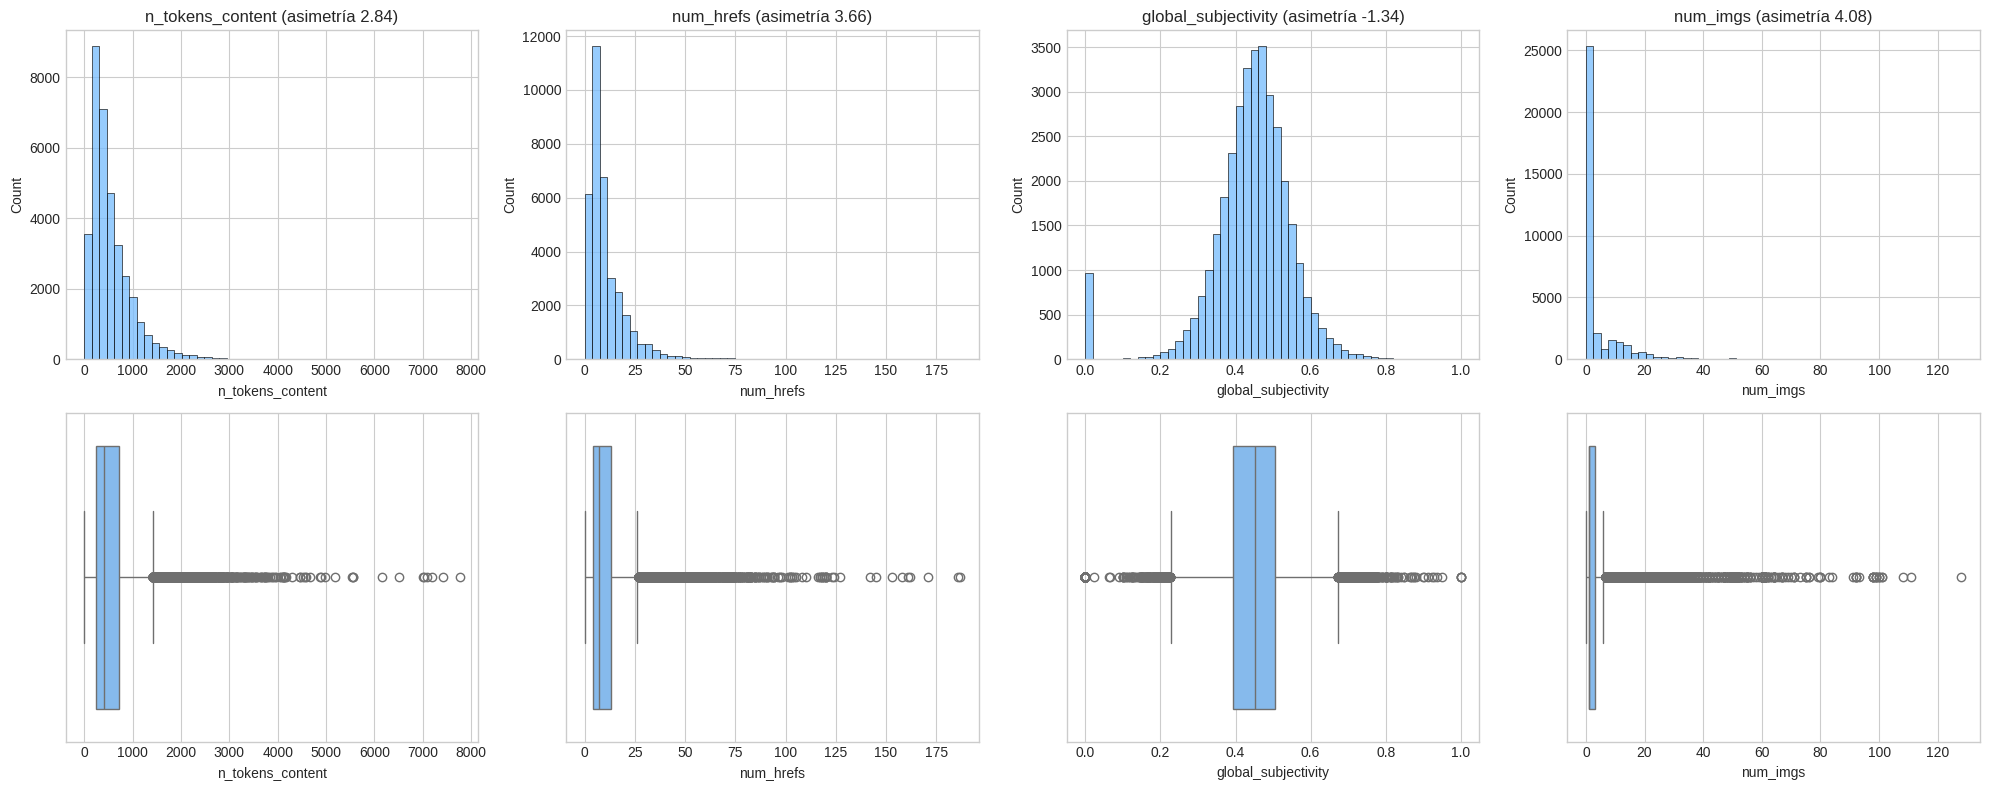

       n_tokens_content  num_hrefs  global_subjectivity  num_imgs
count          35103.00   35103.00             35103.00  35103.00
mean             546.79      10.58                 0.44      4.34
std              462.71      10.77                 0.11      8.09
min                0.00       0.00                 0.00      0.00
25%              250.00       4.00                 0.39      1.00
50%              414.00       7.00                 0.45      1.00
75%              715.00      13.00                 0.51      3.00
max             7764.00     187.00                 1.00    128.00

Correlación con shares: {'n_tokens_content': 0.048, 'num_hrefs': 0.078, 'global_subjectivity': 0.058, 'num_imgs': 0.056}

Train: (23519, 44) | Test: (11584, 44)
Línea base (promedio): RMSE = 1098.9 | MAE = 842.4 | R2 = -0.0000


In [28]:
candidatas = ['n_tokens_content', 'num_hrefs', 'kw_avg_avg', 'global_subjectivity',
              'num_imgs', 'average_token_length', 'n_tokens_title']
cuatro = [v for v in candidatas if v in pred_final.columns][:4]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, v in enumerate(cuatro):
    sns.histplot(mash_final[v], bins=50, ax=axes[0, j], color='xkcd:sky blue')
    axes[0, j].set_title(f'{v} (asimetría {mash_final[v].skew():.2f})')
    sns.boxplot(x=mash_final[v], ax=axes[1, j], color='xkcd:sky blue')
plt.tight_layout(); plt.show()
print(mash_final[cuatro].describe().round(2))
print('\nCorrelación con shares:', mash_final[cuatro].corrwith(mash_final['shares']).round(3).to_dict())

X = mash_final.drop(columns=['shares'])
y = mash_final['shares']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Normalización (media 0, desviación 1) ajustada solo con el entrenamiento
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print(f'\nTrain: {X_train_std.shape} | Test: {X_test_std.shape}')

# Métricas de regresión que se usarán en todos los modelos
resultados = []
def evaluar_reg(nombre, y_real, y_pred):
    r = {'modelo': nombre,
         'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
         'MAE': mean_absolute_error(y_real, y_pred),
         'R2': r2_score(y_real, y_pred)}
    resultados.append(r)
    print(f"{nombre}: RMSE = {r['RMSE']:.1f} | MAE = {r['MAE']:.1f} | R2 = {r['R2']:.4f}")
    return r

# Línea base: predecir siempre el promedio del entrenamiento
evaluar_reg('Línea base (promedio)', y_test, np.full(len(y_test), y_train.mean()))

**Observación:** las cuatro variables elegidas (`n_tokens_content`, `num_hrefs`, `global_subjectivity` y `num_imgs`) muestran distribuciones distintas: las tres de conteo son muy asimétricas hacia la derecha (mediana de 414 palabras pero máximo de 7.764; mediana de 7 enlaces y 1 imagen, con máximos de 187 y 128), mientras `global_subjectivity` es aproximadamente simétrica en torno a 0.45. Ninguna se correlaciona linealmente con shares (|r| < 0.08), lo que anticipa la dificultad de predecir la popularidad. Se normalizaron todas las predictoras ajustando el escalador solo con el entrenamiento (23.519 artículos) y se reservaron 11.584 para test.

**Métricas de evaluación (iguales para todos los modelos):** **RMSE** (error típico, en número de veces compartido; penaliza más los errores grandes) y **MAE** (error absoluto promedio). Se agrega **R²** (proporción de la variabilidad explicada) y una **línea base** que predice siempre el promedio, para dimensionar cuánto aporta cada modelo.

## 8. Random Forest con búsqueda de grilla (5 folds)
Grilla del enunciado: `n_estimators` (10 valores entre 100 y 300) × `max_depth` (10 valores entre 2 y 15) × `max_features` (`sqrt`, `log2`) = 200 combinaciones × 5 folds = 1.000 entrenamientos.

**Implementación eficiente y equivalente a `GridSearchCV`:** en un Random Forest con semilla fija, un bosque de 300 árboles contiene exactamente a los bosques de 100, 122, ..., 278 árboles (son sus primeros árboles), y su predicción es el promedio de los árboles. Por eso, para cada combinación de `max_depth` y `max_features` y cada fold se entrena un solo bosque de 300 árboles y se evalúan los 10 valores de `n_estimators` promediando los primeros *k* árboles. Se obtienen los mismos resultados con 100 entrenamientos en lugar de 1.000. Métrica de selección: RMSE promedio de validación.

In [29]:
grilla_n = np.linspace(100, 300, 10).astype(int)
grilla_depth = np.linspace(2, 15, 10).astype(int)
grilla_mf = ['sqrt', 'log2']
print('n_estimators:', grilla_n, '\nmax_depth:', grilla_depth, '\nmax_features:', grilla_mf)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
folds = list(kf.split(X_train_std))
Xtr_np, ytr_np = X_train_std.values, y_train.values

inicio = time.time()
filas = []
for mf in grilla_mf:
    for d in grilla_depth:
        rmse = np.zeros((len(folds), len(grilla_n)))
        for i, (a, b) in enumerate(folds):
            rf = RandomForestRegressor(n_estimators=grilla_n.max(), max_depth=d, max_features=mf,
                                       random_state=42, n_jobs=-1).fit(Xtr_np[a], ytr_np[a])
            acumulado = np.cumsum([arbol.predict(Xtr_np[b]) for arbol in rf.estimators_], axis=0)
            for j, n in enumerate(grilla_n):
                rmse[i, j] = np.sqrt(mean_squared_error(ytr_np[b], acumulado[n - 1] / n))
        for j, n in enumerate(grilla_n):
            filas.append({'max_features': mf, 'max_depth': d, 'n_estimators': n,
                          'rmse_cv': rmse[:, j].mean(), 'rmse_std': rmse[:, j].std()})
grilla_rf = pd.DataFrame(filas).sort_values('rmse_cv')
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} min | combinaciones evaluadas: {len(grilla_rf)}')
mejor_rf = grilla_rf.iloc[0]
print('\nMejores hiperparámetros:', mejor_rf[['n_estimators', 'max_depth', 'max_features']].to_dict(),
      f"| RMSE CV: {mejor_rf['rmse_cv']:.1f}")
print('\nTop 10 combinaciones:')
print(grilla_rf.head(10).round(1).to_string(index=False))

rf_final = RandomForestRegressor(n_estimators=int(mejor_rf['n_estimators']), max_depth=int(mejor_rf['max_depth']),
                                 max_features=mejor_rf['max_features'], random_state=42, n_jobs=-1)
rf_final.fit(X_train_std, y_train)
print()
evaluar_reg('Random Forest', y_test, rf_final.predict(X_test_std))

n_estimators: [100 122 144 166 188 211 233 255 277 300] 
max_depth: [ 2  3  4  6  7  9 10 12 13 15] 
max_features: ['sqrt', 'log2']
Tiempo de búsqueda: 12.4 min | combinaciones evaluadas: 200

Mejores hiperparámetros: {'n_estimators': 300, 'max_depth': 15, 'max_features': 'log2'} | RMSE CV: 1034.9

Top 10 combinaciones:
max_features  max_depth  n_estimators  rmse_cv  rmse_std
        log2         15           300   1034.9      16.5
        sqrt         15           300   1035.1      15.9
        sqrt         13           277   1035.1      16.1
        log2         15           277   1035.1      16.6
        sqrt         13           233   1035.1      16.0
        sqrt         13           300   1035.1      16.2
        sqrt         13           255   1035.2      16.0
        sqrt         15           277   1035.3      16.0
        sqrt         15           255   1035.3      16.1
        log2         15           233   1035.3      16.4

Random Forest: RMSE = 1022.0 | MAE = 764.4 | R2 = 

**Observación:** la búsqueda (200 combinaciones × 5 folds, 12.4 minutos) elige 300 árboles, profundidad 15 y `max_features = 'log2'`, el modelo más complejo de la grilla, aunque las diez mejores combinaciones son prácticamente equivalentes (RMSE de validación entre 1034.9 y 1035.3). En test obtiene RMSE de 1022.0, MAE de 764.4 y R² de 0.135: reduce el error respecto de la línea base (RMSE 1098.9), pero explica una fracción acotada de la variabilidad.

## 9. Red neuronal Fully Connected con Dropout
Dos capas ocultas de **512 y 384 neuronas** (más de 300 cada una) con ReLU e inicialización He, **Dropout** (0.3) después de cada una y salida lineal de 1 neurona (regresión). La variable objetivo se estandariza para entrenar (estabiliza el descenso del gradiente) y las predicciones se devuelven a la escala original. Pérdida MSE, optimizador Adam y parada temprana sobre un 15% de validación.

Model: "fully_connected_shares"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 512)            │        23,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 384)            │       196,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,417 (861.00 KB)

 Trainable params: 220,417 (861.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 24


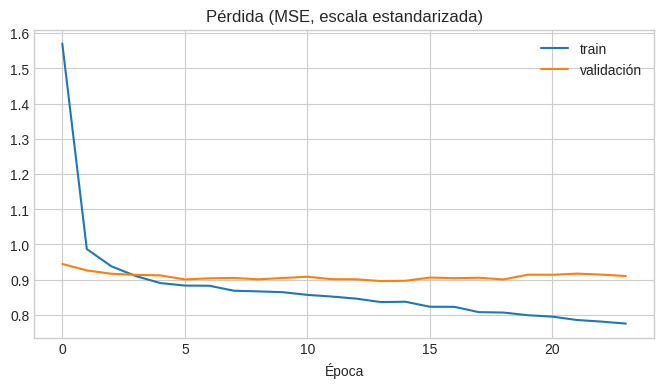

Red Fully Connected: RMSE = 1044.0 | MAE = 760.7 | R2 = 0.0974


In [30]:
y_media, y_desv = y_train.mean(), y_train.std()
keras.utils.set_random_seed(42)
modelo_fc = keras.Sequential([
    keras.Input(shape=(X_train_std.shape[1],)),
    layers.Dense(512, activation='relu', kernel_initializer='he_normal'),
    layers.Dropout(0.3),
    layers.Dense(384, activation='relu', kernel_initializer='he_normal'),
    layers.Dropout(0.3),
    layers.Dense(1)
], name='fully_connected_shares')
modelo_fc.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
modelo_fc.summary()

hist_fc = modelo_fc.fit(X_train_std.values, ((y_train - y_media) / y_desv).values, validation_split=0.15,
                        epochs=100, batch_size=128, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                                                 restore_best_weights=True)])
print('Épocas entrenadas:', len(hist_fc.history['loss']))
plt.figure(figsize=(8, 4))
plt.plot(hist_fc.history['loss'], label='train'); plt.plot(hist_fc.history['val_loss'], label='validación')
plt.title('Pérdida (MSE, escala estandarizada)'); plt.xlabel('Época'); plt.legend(); plt.show()

pred_fc = modelo_fc.predict(X_test_std.values, verbose=0).ravel() * y_desv + y_media
evaluar_reg('Red Fully Connected', y_test, pred_fc)

**Observación:** la red de dos capas ocultas (512 y 384 neuronas) con Dropout se detuvo en la época 24 por parada temprana. En test obtiene RMSE de 1044.0 y R² de 0.097: mejora la línea base, pero queda por debajo de los ensambles de árboles, algo habitual en datos tabulares con variables muy asimétricas. Su MAE (760.7) es similar al de Random Forest, lo que indica que su desventaja proviene de errores mayores en algunos artículos.

## 10. XGBoost con búsqueda de grilla (5 folds)
Grilla del enunciado: `n_estimators` (5) × `learning_rate` (5) × `subsample` (5) × `scale_pos_weight` (2) = 250 combinaciones × 5 folds = 1.250 entrenamientos.

**Implementación eficiente y equivalente:** en boosting, un modelo de 300 árboles contiene a los de 100, 120, 150 y 200 (los árboles se agregan uno tras otro con la misma semilla), y XGBoost permite predecir usando solo los primeros *k* (`iteration_range`). Se entrena un modelo de 300 árboles por combinación del resto de hiperparámetros y fold (250 entrenamientos). Se usa la GPU si está disponible.

**Notas sobre la grilla:** `scale_pos_weight` es un parámetro para clasificación binaria desbalanceada y **no tiene efecto en regresión**, por lo que ambos valores producen resultados idénticos. El valor 0.07 de `learning_rate` probablemente es una errata de 0.007, pero se mantiene tal como lo indica el enunciado.

Tiempo de búsqueda: 3.1 min | combinaciones evaluadas: 250

Mejores hiperparámetros: n_estimators = 300 | learning_rate = 0.02 | subsample = 0.5250 | scale_pos_weight = 0.8 | RMSE CV: 1029.5

Top 10 combinaciones:
 learning_rate  subsample  scale_pos_weight  n_estimators   rmse_cv
          0.02     0.5250               0.8           300 1029.4513
          0.02     0.5250               0.9           300 1029.4513
          0.02     0.7625               0.8           300 1029.7125
          0.02     0.7625               0.9           300 1029.7125
          0.02     0.5250               0.8           200 1030.9789
          0.02     0.5250               0.9           200 1030.9789
          0.02     0.7625               0.8           200 1031.1687
          0.02     0.7625               0.9           200 1031.1687
          0.02     0.2875               0.8           300 1031.5858
          0.02     0.2875               0.9           300 1031.5858

Diferencia máxima de RMSE entre los d

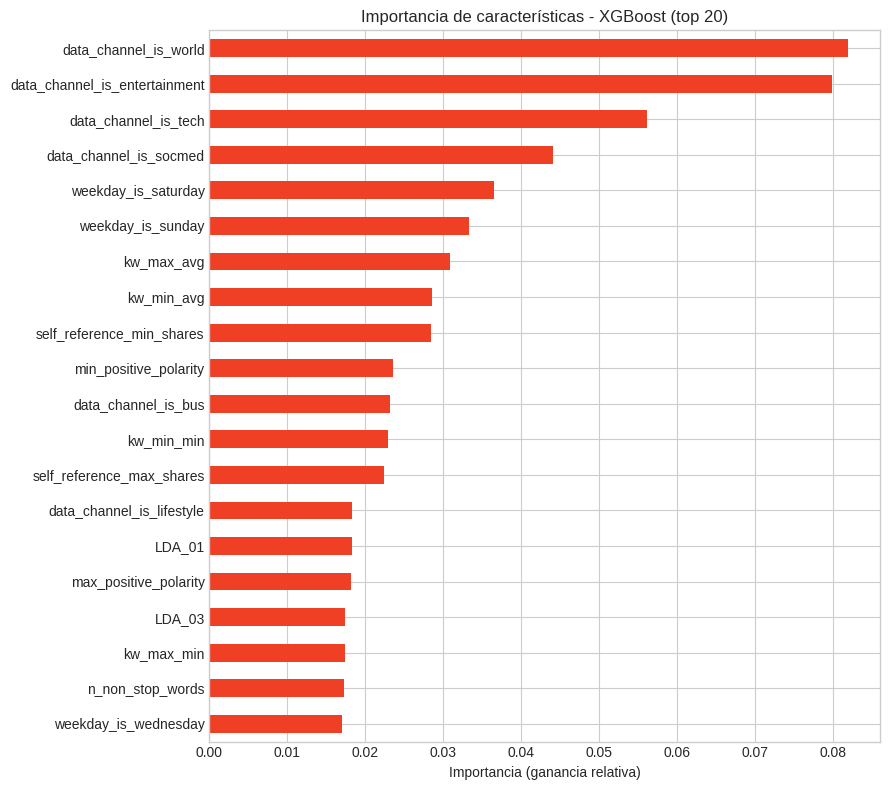

data_channel_is_world            0.0819
data_channel_is_entertainment    0.0799
data_channel_is_tech             0.0561
data_channel_is_socmed           0.0441
weekday_is_saturday              0.0365
weekday_is_sunday                0.0333
kw_max_avg                       0.0308
kw_min_avg                       0.0286
self_reference_min_shares        0.0284
min_positive_polarity            0.0236
dtype: float32


In [31]:
grilla_nx = [100, 120, 150, 200, 300]
grilla_lr = [0.008, 0.07, 0.009, 0.01, 0.02]
grilla_sub = np.linspace(0.05, 1, 5)
grilla_spw = np.linspace(0.8, 0.9, 2)
dispositivo = 'cuda' if GPU else 'cpu'

inicio = time.time()
filas = []
for lr in grilla_lr:
    for sub in grilla_sub:
        for spw in grilla_spw:
            rmse = np.zeros((len(folds), len(grilla_nx)))
            for i, (a, b) in enumerate(folds):
                xgb = XGBRegressor(n_estimators=max(grilla_nx), learning_rate=lr, subsample=sub,
                                   scale_pos_weight=spw, tree_method='hist', device=dispositivo,
                                   random_state=42).fit(Xtr_np[a], ytr_np[a])
                for j, n in enumerate(grilla_nx):
                    p = xgb.predict(Xtr_np[b], iteration_range=(0, n))
                    rmse[i, j] = np.sqrt(mean_squared_error(ytr_np[b], p))
            for j, n in enumerate(grilla_nx):
                filas.append({'learning_rate': lr, 'subsample': sub, 'scale_pos_weight': spw,
                              'n_estimators': n, 'rmse_cv': rmse[:, j].mean()})
grilla_xgb = pd.DataFrame(filas).sort_values('rmse_cv', kind='stable')
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} min | combinaciones evaluadas: {len(grilla_xgb)}')
mejor_xgb = grilla_xgb.iloc[0]
print(f"\nMejores hiperparámetros: n_estimators = {int(mejor_xgb['n_estimators'])} | "
      f"learning_rate = {mejor_xgb['learning_rate']} | subsample = {mejor_xgb['subsample']:.4f} | "
      f"scale_pos_weight = {mejor_xgb['scale_pos_weight']} | RMSE CV: {mejor_xgb['rmse_cv']:.1f}")
print('\nTop 10 combinaciones:')
print(grilla_xgb.head(10).round(4).to_string(index=False))
dif_spw = grilla_xgb.groupby(['learning_rate', 'subsample', 'n_estimators'])['rmse_cv'].agg(lambda s: s.max() - s.min()).max()
print(f'\nDiferencia máxima de RMSE entre los dos valores de scale_pos_weight: {dif_spw:.6f}')

xgb_final = XGBRegressor(n_estimators=int(mejor_xgb['n_estimators']), learning_rate=mejor_xgb['learning_rate'],
                         subsample=mejor_xgb['subsample'], scale_pos_weight=mejor_xgb['scale_pos_weight'],
                         tree_method='hist', device=dispositivo, random_state=42)
xgb_final.fit(X_train_std.values, y_train.values)
print()
evaluar_reg('XGBoost', y_test, xgb_final.predict(X_test_std.values))

importancia = pd.Series(xgb_final.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 8))
importancia.head(20)[::-1].plot(kind='barh', color='xkcd:tomato')
plt.title('Importancia de características - XGBoost (top 20)'); plt.xlabel('Importancia (ganancia relativa)')
plt.tight_layout(); plt.show()
print(importancia.head(10).round(4))

**Observación:** la mejor combinación es learning_rate = 0.02, subsample = 0.525 y 300 árboles, con RMSE de validación de 1029.5. Como en Random Forest, la búsqueda elige el learning_rate más alto razonable y el máximo de árboles: con tasas pequeñas el modelo necesita más iteraciones para converger. Los dos valores de `scale_pos_weight` producen resultados idénticos (diferencia 0), confirmando que no aplica en regresión. En test, XGBoost obtiene el mejor desempeño: RMSE 1015.3, MAE 752.0 y R² 0.146. Las variables más importantes son los canales temáticos (world, entertainment, tech, social media), la publicación en sábado o domingo y las métricas de palabras clave.

## 11. Bagging heterogéneo
Se usa la función `bagging_het` del archivo `util_bagging.py` con tres estimadores de naturaleza distinta: un **árbol de decisión** (profundidad 8), **K vecinos más cercanos** (k = 15) y una **regresión Ridge**. Se generan 30 muestras bootstrap y en cada una se entrena un estimador elegido al azar.

**Observación sobre la función:** `bagging_het` combina las predicciones por **mayoría de votos (moda)**, criterio pensado para clasificación. En regresión las predicciones son valores continuos, por lo que la moda no es un agregador adecuado. La función devuelve también la matriz con las predicciones de cada estimador (`yhat_test`), con la que se calcula el **promedio**, que es el agregador correcto para regresión. Se reportan ambos para mostrar la diferencia.

In [32]:
import util_bagging as ubagging

estimadores = [DecisionTreeRegressor(max_depth=8, random_state=42),
               KNeighborsRegressor(n_neighbors=15),
               Ridge(alpha=1.0)]
np.random.seed(42)
inicio = time.time()
modelos_bag, yhat_bag, yhat_moda, idx_oob = ubagging.bagging_het(X_train_std, y_train, 30, estimadores, X_test_std)
print(f'Tiempo: {(time.time() - inicio) / 60:.1f} min | matriz de predicciones: {yhat_bag.shape} | '
      f'observaciones fuera de bolsa: {len(idx_oob)}')

pred_bag_prom = yhat_bag.mean(axis=1)
evaluar_reg('Bagging heterogéneo (promedio)', y_test, pred_bag_prom)
evaluar_reg('Bagging heterogéneo (moda, función original)', y_test, yhat_moda.values)

Tiempo: 0.5 min | matriz de predicciones: (11584, 30) | observaciones fuera de bolsa: 23519
Bagging heterogéneo (promedio): RMSE = 1036.8 | MAE = 764.6 | R2 = 0.1099
Bagging heterogéneo (moda, función original): RMSE = 1187.1 | MAE = 773.0 | R2 = -0.1669


**Observación:** el promedio de los 30 estimadores heterogéneos (árboles, K vecinos y Ridge) obtiene RMSE de 1036.8 y R² de 0.110, mejor que la red Fully Connected pero por debajo de Random Forest y XGBoost. La agregación por moda de la función original da un R² negativo (peor que predecir siempre el promedio), lo que confirma que la moda no es un agregador adecuado para regresión. El conteo de observaciones fuera de bolsa coincide con el total del entrenamiento porque la función acumula la unión de las excluidas en las 30 muestras.

## Comparación de modelos

Parte B - Regresión de shares (conjunto de test):
                                                RMSE    MAE      R2
modelo                                                             
XGBoost                                       1015.3  752.0  0.1463
Random Forest                                 1022.0  764.4  0.1351
Bagging heterogéneo (promedio)                1036.8  764.6  0.1099
Red Fully Connected                           1044.0  760.7  0.0974
Línea base (promedio)                         1098.9  842.4 -0.0000
Bagging heterogéneo (moda, función original)  1187.1  773.0 -0.1669


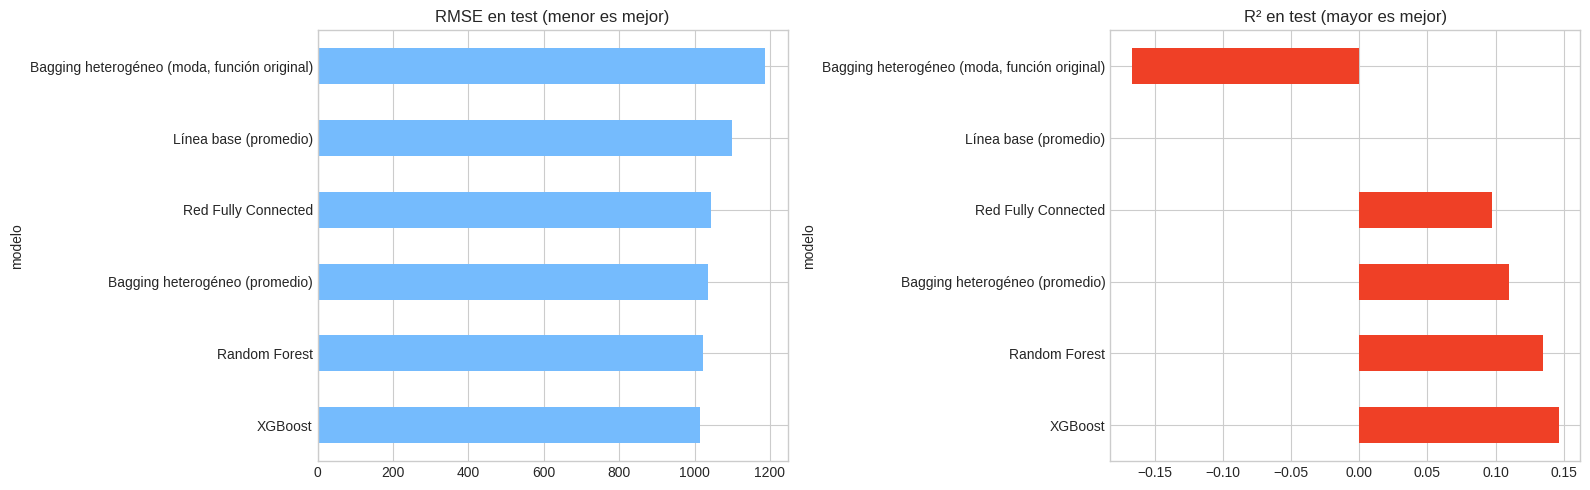


Parte A - LSTM (clasificación de noticias): accuracy test = 0.8576 | AUC = 0.9292


In [33]:
tabla_final = pd.DataFrame(resultados).drop_duplicates('modelo', keep='last').set_index('modelo')
tabla_final = tabla_final.sort_values('RMSE').round({'RMSE': 1, 'MAE': 1, 'R2': 4})
print('Parte B - Regresión de shares (conjunto de test):')
print(tabla_final.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
tabla_final['RMSE'].plot(kind='barh', ax=axes[0], color='xkcd:sky blue'); axes[0].set_title('RMSE en test (menor es mejor)')
tabla_final['R2'].plot(kind='barh', ax=axes[1], color='xkcd:tomato'); axes[1].set_title('R² en test (mayor es mejor)')
plt.tight_layout(); plt.show()

print(f'\nParte A - LSTM (clasificación de noticias): accuracy test = {acc_lstm:.4f} | AUC = {auc_lstm:.4f}')

## Conclusiones

### Parte A · Clasificación de noticias falsas con LSTM
- El archivo `news1.csv` requirió limpieza: 74 filas mal formadas y **2.643 noticias duplicadas** (42% de las filas válidas). Se eliminaron los duplicados para evitar que una misma noticia quedara en entrenamiento y test, quedando 3.660 noticias balanceadas (50.4% REAL, 49.6% FAKE).
- Las noticias reales se concentran en la política electoral concreta (*obama*, *republican*, *sanders*, *cruz*, *voters*), mientras las falsas usan términos más generales y de confrontación (*hillary*, *media*, *war*, *government*, *world*), y son más cortas (mediana de 452 vs 776 palabras).
- El Word2Vec de Google cubrió el 58.9% del vocabulario de 70.660 palabras; las restantes (nombres propios, cifras y palabras con apóstrofes tipográficos) quedan con vector nulo.
- La red de **tres capas LSTM con Dropout**, con el embedding pre-entrenado congelado, alcanzó **85.8% de accuracy y AUC de 0.929 en test**, superando la meta de 80%, con 14 épocas (parada temprana) y desempeño equilibrado entre clases (F1 de 0.856 para REAL y 0.859 para FAKE).
- En las siete noticias nuevas acertó 5. Sus errores (una sátira clasificada como real y una noticia real alarmista clasificada como falsa) muestran que el modelo aprende **vocabulario y estilo**, no la veracidad de los hechos.

### Parte B · Predicción de la cantidad de veces que se comparte un artículo

| Modelo | RMSE | MAE | R² |
|---|---|---|---|
| **XGBoost** | **1015.3** | **752.0** | **0.146** |
| Random Forest | 1022.0 | 764.4 | 0.135 |
| Bagging heterogéneo (promedio) | 1036.8 | 764.6 | 0.110 |
| Red Fully Connected | 1044.0 | 760.7 | 0.097 |
| Línea base (promedio) | 1098.9 | 842.4 | 0.000 |
| Bagging heterogéneo (moda, función original) | 1187.1 | 773.0 | −0.167 |

- **XGBoost es el mejor modelo** en RMSE y R², seguido de cerca por Random Forest: los ensambles de árboles capturan mejor las relaciones no lineales entre las características y la popularidad. Ambas búsquedas eligieron los modelos más capaces de la grilla (300 árboles; profundidad 15 en Random Forest y learning_rate de 0.02 en XGBoost), lo que sugiere que ampliar los rangos podría mejorar algo más.
- **Todos los modelos mejoran la línea base, pero de forma modesta:** el mejor explica solo el 14.6% de la variabilidad y reduce el error típico en ~84 compartidos (de 1.099 a 1.015). La popularidad de un artículo depende en gran medida de factores que no están en los datos (contingencia, difusión en redes, autor), por lo que es intrínsecamente difícil de predecir con estas variables.
- Las características más importantes para XGBoost son el **canal temático** (world, entertainment, tech, social media), la **publicación en fin de semana** y el desempeño histórico de las **palabras clave** y de los artículos referenciados.
- La **red Fully Connected** queda por debajo de los ensambles de árboles: con datos tabulares y variables muy asimétricas, los árboles suelen rendir mejor que las redes densas.
- El **Bagging heterogéneo** con promedio queda en un punto intermedio. Con la agregación por **moda** de la función entregada, el resultado es peor que la línea base (R² negativo): la moda es un criterio de votación para clasificación y no es adecuada para valores continuos.

### Decisiones metodológicas y limitaciones
- Se eliminaron duplicados en `news1.csv` y se ajustaron los escaladores solo con datos de entrenamiento, para evitar fugas de información.
- Las búsquedas de grilla de Random Forest y XGBoost se implementaron evaluando subconjuntos de árboles de un modelo de 300 (resultados equivalentes a `GridSearchCV`, verificados previamente), reduciendo el tiempo de cómputo de horas a minutos.
- `scale_pos_weight` no tiene efecto en regresión (ambos valores producen resultados idénticos) y el valor 0.07 de `learning_rate` parece una errata de 0.007; se mantuvieron tal como los indica el enunciado.
- La función `bagging_het` reutiliza los mismos objetos estimadores en cada iteración, por lo que la lista de modelos que devuelve no conserva los modelos de cada muestra bootstrap; las predicciones se calculan dentro de la función, por lo que no afecta los resultados reportados.